## Lasso

##### Notes

The alpha parameter in Lasso regression controls the strength of the L1 regularization penalty.

##### Model

train 1992-03-31 to 2014-12-31  (92, 22)
test  2015-03-31 to 2025-12-31  (44, 22)
best params: {'lasso__alpha': np.float64(0.02592943797404667)}
best CV root_mean_squared_error: 0.3454
recorded 'Lasso' -> /workspaces/DX799-O1/model_data/results


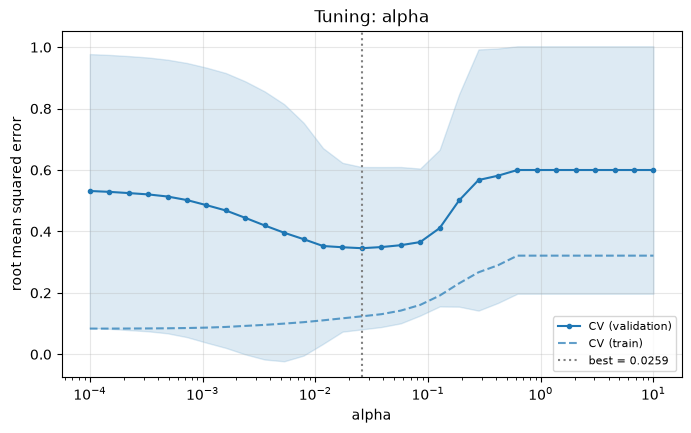

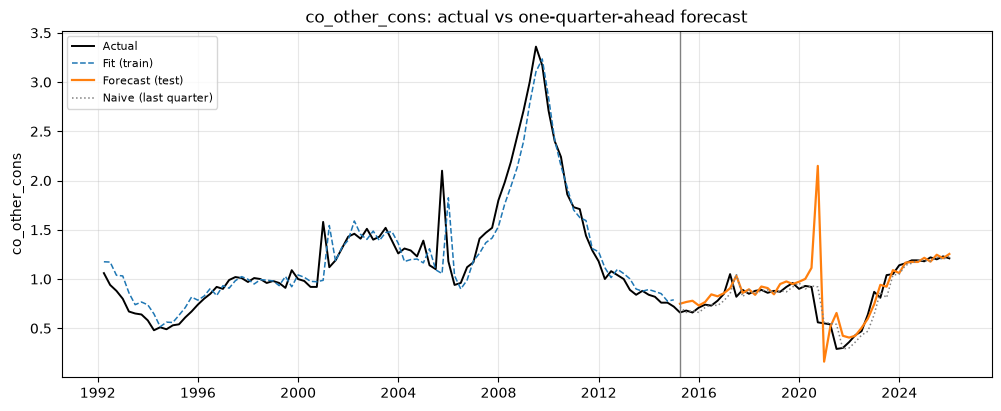

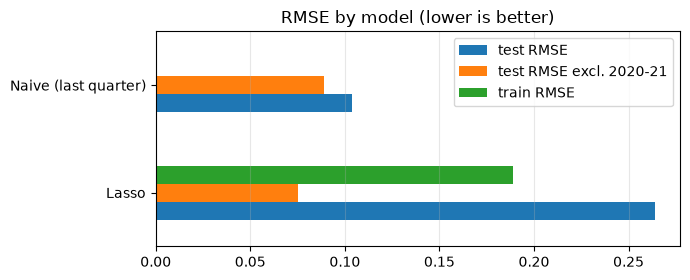

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

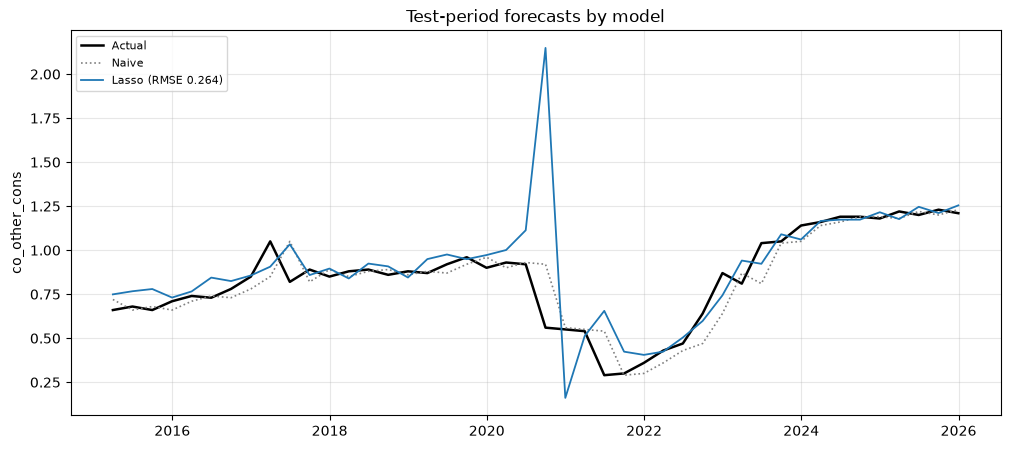

In [1]:
    from prep import *
    from sklearn.linear_model import Lasso

    X_train, X_test, y_train, y_test, meta = load_model_data()

    # 1) build + tune (grid lives in the notebook)
    pipe = make_pipeline(*preprocess(scale=True), Lasso(max_iter=50_000))
    grid = {"lasso__alpha": np.logspace(-4, 1, 30)}
    search = tune(pipe, grid, X_train, y_train)

    # 2) see how the hyperparameter changes performance
    tuning_table(search)
    plot_tuning(search, "lasso__alpha")

    # 3) score the best model, look at it, save it for the final comparison
    best = search.best_estimator_
    score(best, X_train, X_test, y_train, y_test)
    plot_forecast(best, X_train, X_test, y_train, y_test)
    record("Lasso", best, X_train, X_test, y_train, y_test, search=search)

    # 4) any notebook (or a final one): compare every recorded model
    compare()
    plot_forecasts()

##### Export CSV 

In [2]:
export_predictions(best, X_train, X_test, y_train, y_test, name="Lasso")

saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Lasso_predictions.csv


,set,actual,predicted,error (pred - actual),abs error,naive (last quarter)
date,,,,,,
1992-03-31,train,1.06,1.175192,0.115192,0.115192,1.05
1992-06-30,train,0.94,1.172256,0.232256,0.232256,1.06
1992-09-30,train,0.88,1.038267,0.158267,0.158267,0.94
1992-12-31,train,0.80,1.031249,0.231249,0.231249,0.88
1993-03-31,train,0.67,0.860514,0.190514,0.190514,0.80
...,...,...,...,...,...,...
2024-12-31,test,1.18,1.215491,0.035491,0.035491,1.19
2025-03-31,test,1.22,1.176509,-0.043491,0.043491,1.18
2025-06-30,test,1.20,1.246390,0.046390,0.046390,1.22
